In [1]:
import pathlib 
import numpy as np
import scipy as sp
from matplotlib import pyplot as plt

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [42]:
def plot_single_sess(pp, fig, ax, color):
    # frame_times = np.array(pp.metadata['frame_times']).squeeze()
    frame_times = np.array(pp.metadata['frame_times']).mean(axis=1)

    stim_times = [pp.metadata['mark_points']['initial_delay']/1000,]
    for i in range(1, pp.metadata['mark_points']['repetitions']):
        stim_times.append(stim_times[-1] + pp.metadata['mark_points']['duration']/1000 + pp.metadata['mark_points']['inter_point_delay']/1000)

    responses = []
    smallest_list = 1E6
    for stim_time in stim_times[1:]:
        idx = np.argmin(np.abs(frame_times - stim_time))
        id_start = np.argmin(np.abs(frame_times - (stim_time+2 - 5)))
        id_end = np.argmin(np.abs(frame_times - (stim_time+2 + 8)))
        
        # responses.append(pp.timeseries['outer_ring'][-1,0,id_start:id_end][np.newaxis,:])
        responses.append(pp.timeseries['outer_ring'][-1,:,id_start:id_end].mean(axis=0)[np.newaxis,:])
        smallest_list = min(smallest_list, responses[-1].shape[1]) 
    responses = np.vstack([resp[:,:smallest_list] for resp in responses])



    dt = np.mean(frame_times[1:] - frame_times[:-1])

    time = np.linspace(-5, 8, num = responses.shape[1])
    mask = (time >= -.2) & (time <= .6)
    baseline_mask = time < -.1
    responses[:,mask] = np.nan
    baseline = np.nanmean(responses[:,baseline_mask],axis=1, keepdims=True)
    responses /= baseline

    mu = np.nanmean(responses, axis=0)-1
    sem = sp.stats.sem(responses, axis=0, nan_policy='omit')
    ax.plot(time, mu, color=color, alpha=.4)
    ax.fill_between(time, mu-sem, mu+sem, color=color, alpha=.5)

/tmp/ipykernel_1936229/3367534455.py:32: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(responses, axis=0)-1
/tmp/ipykernel_1936229/3367534455.py:33: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  sem = sp.stats.sem(responses, axis=0, nan_policy='omit')


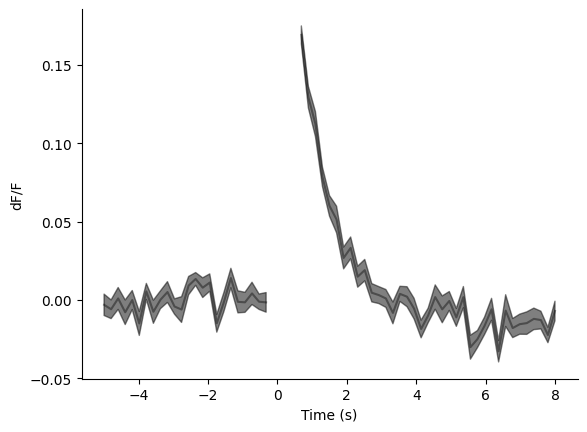

In [53]:
genotype_dir = "R20A02_R56H10_split_CsChrimsontdT_synaptopHluorinVAMP2/pilots"
date = "17_12_2025"
fly = 'fly1'

sessions = [
    'baseline_opto_response-001', 
    # 'baseline_opto_response-002', 
    # 'post_perfusion_opto_response-003',
    # 'post_perfusion_opto_response-005',
    # 'post_OAperfusion_opto_response-006',
    # 'post_OAperfusion_opto_response-007',
    ]

# sessions = [
#     'baseline_opto_response-001', 
#     'baseline_opto_response-002', 
#     'postForskolin_opto_response-003',
#     'postForskolin_opto_response-004',
#     ]
fig, ax = plt.subplots()
cmap = plt.get_cmap('Greys_r')
for i, sess in enumerate(sessions):
    outdir = pathlib.PurePath(f'/media/mplitt/SSD_storage/2P_scratch/{genotype_dir}/{date}/{fly}/{sess}/preprocess.pkl')
    # print(outdir)
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('dF/F')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    

    plot_single_sess(pp, fig, ax, color=cmap(i/len(sessions)))
    fig.savefig(f'/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/scratch/synaptopHluorin_example.pdf', bbox_inches='tight')
    

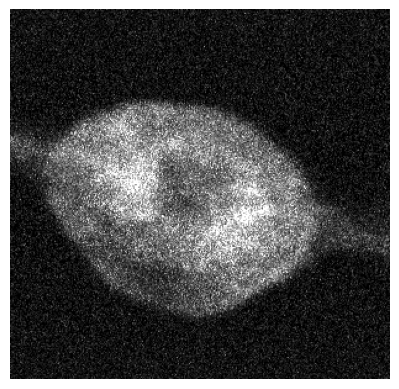

In [51]:
fig, ax = plt.subplots()
refImg = np.amax(pp.ref_img[1,:,:,::-1],axis=0).T
ax.imshow(refImg, cmap='gray', vmin=0, vmax=np.percentile(refImg, 99))
ax.axis('off')
fig.savefig(f'/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/scratch/synaptopHluorin_example_refimg.pdf')
# pp.ref_img.shape

In [54]:
pp.metadata['mark_points']

{'iterations': 1,
 'iteration_delay': 1000.0,
 'repetitions': 20,
 'uncaging_laser': '617',
 'trigger': 'PFI1',
 'trigger_freq': 'None',
 'trigger_count': 1,
 'uncaging_power': 50,
 'custom_laser_power': None,
 'initial_delay': 5000.0,
 'inter_point_delay': 9700.0,
 'duration': 300.0,
 'spiral_revolutions': 1.0,
 'indices': '9',
 'points_list': [{'Index': 9.0,
   'X': 0.408462056177937,
   'Y': 0.445766610553391,
   'IsSpiral': True,
   'SpiralWidth': 0.100955065358738,
   'SpiralHeight': 0.0983328558689003,
   'SpiralSizeInMicrons': 10.0}]}

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_1936229/420280269.py:29: RuntimeWarning: Mean of empty slice
  baseline = np.nanmean(responses[:,baseline_mask],axis=1, keepdims=True)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
 

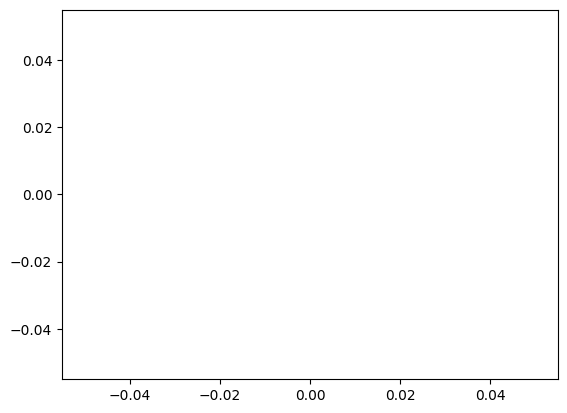

In [32]:
genotype_dir = 'R27F02Gal4_iGABASnFR2_R20A02LexA_CsChrimson/pilot'
date = "14_05_2026"
fly = 'fly2'

sessions = [
    'baseline-000', 
    'bath_ctrl-001',
    'bath_ctrl-002',
    ]
fig, ax = plt.subplots()
cmap = plt.get_cmap('cool')
for i, sess in enumerate(sessions):
    outdir = pathlib.PurePath(f'/media/mplitt/SSD_storage/2P_scratch/{genotype_dir}/{date}/{fly}/{sess}/preprocess.pkl')
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)

    
    plot_single_sess(pp, fig, ax, color=cmap(i/len(sessions)))
    